# 🛡️ AE-WGAN : Anomaly-Based Network Intrusion Detection System (CORRIGÉ)

**Basé sur :** Arafah et al. (2025), *"AE-WGAN: A Novel Approach for Anomaly-Based Intrusion Detection"*, Applied Soft Computing 168.

### Corrections appliquées par rapport à la version précédente :
1. **Generator** : 3 couches (40→80→120→output) au lieu de (64→output) — fidèle au paper
2. **Critic** : 3 couches (80→40→1) au lieu de (16→1)
3. **AE intégré au WGAN** : le Critic reçoit les données encodées (AE) comme "real" au lieu des données brutes
4. **Optimiseur Adamax** (lr=9e-5) au lieu d'Adam — conforme au paper
5. **101 epochs** WGAN au lieu de 100
6. **Activation sigmoid** sur la dernière couche du Generator (données [0,1])
7. **Architectures classifieurs** fidèles à Table 4 du paper (NSL-KDD)
8. **Preprocessing** : features ANOVA conformes au paper (Table 5)

## 1. Installation et montage Drive

In [13]:
# Décommenter si Google Colab
from google.colab import drive
drive.mount('/content/drive')

!pip install -q tensorflow numpy pandas scikit-learn matplotlib scipy

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Téléchargement du dataset NSL-KDD

In [14]:
import os
import urllib.request

url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
files = {
    "KDDTrain+.txt": url + "KDDTrain%2B.txt",
    "KDDTest+.txt": url + "KDDTest%2B.txt",
}

for fname, furl in files.items():
    if not os.path.exists(fname):
        print(f"Téléchargement {fname}...")
        urllib.request.urlretrieve(furl, fname)
        print(f"  ✅ {fname} téléchargé")
    else:
        print(f"  ℹ️ {fname} existe déjà")

print("\n✅ Dataset NSL-KDD prêt")

  ℹ️ KDDTrain+.txt existe déjà
  ℹ️ KDDTest+.txt existe déjà

✅ Dataset NSL-KDD prêt


## 3. Imports et configuration

In [15]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score)
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import cdist

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Reproductibilité
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. Configuration NSL-KDD

In [16]:
# ============================================================
# CONFIGURATION NSL-KDD
# ============================================================

NSL_KDD_COLUMNS = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root',
    'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate',
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'label', 'difficulty_level'
]

NSL_KDD_ATTACK_MAP = {
    'normal': 'Normal',
    'back': 'DoS', 'land': 'DoS', 'neptune': 'DoS', 'pod': 'DoS',
    'smurf': 'DoS', 'teardrop': 'DoS', 'mailbomb': 'DoS', 'apache2': 'DoS',
    'processtable': 'DoS', 'udpstorm': 'DoS',
    'satan': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 'portsweep': 'Probe',
    'mscan': 'Probe', 'saint': 'Probe',
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L',
    'multihop': 'R2L', 'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L',
    'xlock': 'R2L', 'xsnoop': 'R2L', 'snmpguess': 'R2L', 'snmpgetattack': 'R2L',
    'httptunnel': 'R2L', 'sendmail': 'R2L', 'named': 'R2L', 'worm': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'rootkit': 'U2R',
    'perl': 'U2R', 'sqlattack': 'U2R', 'xterm': 'U2R', 'ps': 'U2R',
}

# Paper: ANOVA sélectionne 24 features sur NSL-KDD
NSL_KDD_N_FEATURES = 24

print("✅ Configuration chargée")

✅ Configuration chargée


## 5. Preprocessing (fidèle au paper)

Pipeline :
1. **Data Cleaning** : suppression features constantes et quasi-constantes
2. **Ordinal Encoding** : conversion des features catégorielles
3. **Min-Max Scaling** : normalisation [0, 1]
4. **ANOVA Feature Selection** : 41 → 24 features

In [17]:
# ============================================================
# PREPROCESSING FUNCTIONS
# ============================================================

def remove_constant_features(df, threshold=0.01):
    """Supprime features constantes et quasi-constantes."""
    removed = []
    for col in df.columns:
        if df[col].nunique() <= 1:
            removed.append(col)
            continue
        dominant_freq = df[col].value_counts(normalize=True).iloc[0]
        if dominant_freq >= (1 - threshold):
            removed.append(col)
    df_cleaned = df.drop(columns=removed)
    print(f"  Supprimé {len(removed)} features: {removed}")
    return df_cleaned, removed

def apply_ordinal_encoding(df_train, df_test=None):
    """Encodage ordinal des features catégorielles."""
    cat_cols = df_train.select_dtypes(include=['object', 'category']).columns.tolist()
    if not cat_cols:
        return df_train, df_test, None
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    df_train_enc = df_train.copy()
    df_train_enc[cat_cols] = encoder.fit_transform(df_train[cat_cols])
    df_test_enc = None
    if df_test is not None:
        df_test_enc = df_test.copy()
        df_test_enc[cat_cols] = encoder.transform(df_test[cat_cols])
    print(f"  Encodé {len(cat_cols)} features catégorielles: {cat_cols}")
    return df_train_enc, df_test_enc, encoder

def apply_minmax_scaling(X_train, X_test=None):
    """Min-Max Scaling [0, 1]."""
    scaler = MinMaxScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test) if X_test is not None else None
    print(f"  Features normalisées [0, 1]")
    return X_train_s, X_test_s, scaler

def apply_anova_selection(X_train, y_train, X_test=None, n_features=24, feature_names=None):
    """Sélection ANOVA (SelectKBest avec f_classif)."""
    selector = SelectKBest(score_func=f_classif, k=n_features)
    X_train_sel = selector.fit_transform(X_train, y_train)
    X_test_sel = selector.transform(X_test) if X_test is not None else None
    mask = selector.get_support()
    selected = [feature_names[i] for i in range(len(feature_names)) if mask[i]] if feature_names else []
    print(f"  Sélectionné {n_features} features sur {X_train.shape[1]}")
    if selected:
        print(f"  Features: {selected}")
    return X_train_sel, X_test_sel, selector, selected

print("✅ Fonctions de preprocessing définies")

✅ Fonctions de preprocessing définies


In [18]:
# ============================================================
# EXÉCUTION DU PREPROCESSING
# ============================================================

print("=" * 60)
print("PREPROCESSING NSL-KDD")
print("=" * 60)

# Charger les données
df_train = pd.read_csv("KDDTrain+.txt", header=None, names=NSL_KDD_COLUMNS)
df_test = pd.read_csv("KDDTest+.txt", header=None, names=NSL_KDD_COLUMNS)
print(f"\nTraining set: {df_train.shape}")
print(f"Testing set:  {df_test.shape}")

# Supprimer difficulty_level
df_train = df_train.drop(columns=['difficulty_level'], errors='ignore')
df_test = df_test.drop(columns=['difficulty_level'], errors='ignore')

# Extraire les labels
df_train['label'] = df_train['label'].str.strip().str.rstrip('.')
df_test['label'] = df_test['label'].str.strip().str.rstrip('.')

y_train_cat = df_train['label'].map(NSL_KDD_ATTACK_MAP).fillna('Unknown')
y_test_cat = df_test['label'].map(NSL_KDD_ATTACK_MAP).fillna('Unknown')
y_train_detail = df_train['label'].copy()
y_test_detail = df_test['label'].copy()

X_train_df = df_train.drop(columns=['label'])
X_test_df = df_test.drop(columns=['label'])

print(f"\nDistribution (train):")
print(y_train_cat.value_counts())
print(f"\nDistribution (test):")
print(y_test_cat.value_counts())

# Step 1: Data Cleaning
print(f"\n--- Step 1: Data Cleaning ---")
X_train_cleaned, removed = remove_constant_features(X_train_df)
X_test_cleaned = X_test_df.drop(columns=removed, errors='ignore')

# Step 2: Ordinal Encoding
print(f"\n--- Step 2: Ordinal Encoding ---")
X_train_enc, X_test_enc, encoder = apply_ordinal_encoding(X_train_cleaned, X_test_cleaned)
feature_names = X_train_enc.columns.tolist()

# Step 3: Min-Max Scaling
print(f"\n--- Step 3: Min-Max Scaling ---")
X_train_scaled, X_test_scaled, scaler = apply_minmax_scaling(
    X_train_enc.values, X_test_enc.values)

# Step 4: ANOVA Feature Selection
print(f"\n--- Step 4: ANOVA Feature Selection ---")
le_anova = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
y_train_enc = le_anova.fit_transform(y_train_cat.values.reshape(-1, 1)).ravel()

X_train_final, X_test_final, selector, selected_features = apply_anova_selection(
    X_train_scaled, y_train_enc, X_test_scaled,
    n_features=NSL_KDD_N_FEATURES, feature_names=feature_names)

INPUT_DIM = X_train_final.shape[1]  # = 24
print(f"\n✅ Preprocessing terminé!")
print(f"   Train: {X_train_final.shape}, Test: {X_test_final.shape}")

PREPROCESSING NSL-KDD

Training set: (125973, 43)
Testing set:  (22544, 43)

Distribution (train):
label
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Distribution (test):
label
Normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64

--- Step 1: Data Cleaning ---
  Supprimé 13 features: ['land', 'wrong_fragment', 'urgent', 'num_failed_logins', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login']

--- Step 2: Ordinal Encoding ---
  Encodé 3 features catégorielles: ['protocol_type', 'service', 'flag']

--- Step 3: Min-Max Scaling ---
  Features normalisées [0, 1]

--- Step 4: ANOVA Feature Selection ---
  Sélectionné 24 features sur 28
  Features: ['duration', 'protocol_type', 'service', 'flag', 'hot', 'logged_in', 'count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror

## 6. Architecture AE-WGAN (CORRIGÉE — fidèle au paper)

### Corrections majeures :
- **Autoencoder** : Encoder (24→20→16) + Decoder (16→20→24), ReLU
- **Generator** : z(32) → Dense(40, relu) → Dense(80, relu) → Dense(120, relu) → Dense(24, sigmoid)
- **Critic** : input(24) → Dense(80, relu) → Dense(40, relu) → Dense(1, linear)
- **Optimiseur** : Adamax (lr=9e-5) au lieu d'Adam
- **Epochs** : 101 (paper) au lieu de 100
- Le Critic reçoit les données **encodées par l'AE** comme "réelles" (pas les données brutes)

In [19]:
# ============================================================
# DENOISING AUTOENCODER (Paper: Encoder 24→20→16, Decoder 16→20→24)
# ============================================================

class DenoisingAutoencoder:
    def __init__(self, input_dim, latent_dim=16, intermediate_dim=20):
        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # Encoder: 24 → 20 → 16
        inp = layers.Input(shape=(input_dim,))
        x = layers.Dense(intermediate_dim, activation='relu')(inp)
        encoded = layers.Dense(latent_dim, activation='relu')(x)
        self.encoder = Model(inp, encoded, name='encoder')

        # Decoder: 16 → 20 → 24
        lat_inp = layers.Input(shape=(latent_dim,))
        x = layers.Dense(intermediate_dim, activation='relu')(lat_inp)
        decoded = layers.Dense(input_dim, activation='sigmoid')(x)  # sigmoid car données [0,1]
        self.decoder = Model(lat_inp, decoded, name='decoder')

        # Full AE
        ae_inp = layers.Input(shape=(input_dim,))
        ae_out = self.decoder(self.encoder(ae_inp))
        self.autoencoder = Model(ae_inp, ae_out, name='autoencoder')
        # Paper: Adamax lr=9e-5
        self.autoencoder.compile(
            optimizer=tf.keras.optimizers.Adamax(learning_rate=9e-5),
            loss='mse'
        )

    def train(self, X, epochs=101, batch_size=32, verbose=0):
        """Train avec bruit (denoising)."""
        X_noisy = np.clip(X + 0.1 * np.random.normal(size=X.shape), 0, 1)
        return self.autoencoder.fit(
            X_noisy, X, epochs=epochs,
            batch_size=batch_size, validation_split=0.1, verbose=verbose
        )

    def encode(self, X):
        return self.encoder.predict(X, verbose=0)

    def reconstruct(self, X):
        return self.autoencoder.predict(X, verbose=0)

print("✅ DenoisingAutoencoder défini (24→20→16→20→24)")

✅ DenoisingAutoencoder défini (24→20→16→20→24)


In [20]:
# ============================================================
# WGAN GENERATOR & CRITIC (CORRIGÉ — fidèle au paper)
# ============================================================

class WGANGenerator(Model):
    """
    Paper: z(32) → Dense(40, relu) → Dense(80, relu) → Dense(120, relu) → Dense(output_dim, sigmoid)
    3 hidden layers + output layer conforme à la description prose du paper.
    """
    def __init__(self, noise_dim, output_dim):
        super().__init__()
        self.net = Sequential([
            layers.Dense(40, activation='relu', input_shape=(noise_dim,)),
            layers.Dense(80, activation='relu'),
            layers.Dense(120, activation='relu'),
            layers.Dense(output_dim, activation='sigmoid'),  # sigmoid car données [0,1]
        ])

    def call(self, z):
        return self.net(z)


class WGANCritic(Model):
    """
    Paper: input → Dense(80, relu) → Dense(40, relu) → Dense(1, linear)
    """
    def __init__(self, input_dim):
        super().__init__()
        self.net = Sequential([
            layers.Dense(80, activation='relu', input_shape=(input_dim,)),
            layers.Dense(40, activation='relu'),
            layers.Dense(1),  # Linear output (Wasserstein)
        ])

    def call(self, x):
        return self.net(x)

print("✅ Generator (32→40→80→120→24) et Critic (24→80→40→1) définis")

✅ Generator (32→40→80→120→24) et Critic (24→80→40→1) définis


In [21]:
# ============================================================
# AE-WGAN COMBINED MODEL (CORRIGÉ)
# ============================================================
# Corrections clés :
# 1. Le Critic compare données encodées (AE) vs générées
# 2. Optimiseur Adamax (lr=9e-5)
# 3. 101 epochs par défaut
# 4. Gradient penalty WGAN-GP
# ============================================================

class AEWGAN:
    def __init__(self, input_dim, noise_dim=32, latent_dim=16,
                 intermediate_dim=20, n_critic=5, gp_weight=10.0, lr=9e-5):
        self.input_dim = input_dim
        self.noise_dim = noise_dim
        self.n_critic = n_critic
        self.gp_weight = gp_weight

        # AE : Encoder (24→20→16), Decoder (16→20→24)
        self.ae = DenoisingAutoencoder(input_dim, latent_dim, intermediate_dim)

        # Generator : z(32) → 40 → 80 → 120 → output_dim(24)
        self.generator = WGANGenerator(noise_dim, input_dim)

        # Critic : input(24) → 80 → 40 → 1
        self.critic = WGANCritic(input_dim)

        # Paper: Adamax optimizer
        self.gen_optimizer = tf.keras.optimizers.Adamax(learning_rate=lr)
        self.critic_optimizer = tf.keras.optimizers.Adamax(learning_rate=lr)

        self.history = {'ae_loss': [], 'critic_loss': [], 'gen_loss': [], 'w_dist': []}

    def gradient_penalty(self, real, fake, batch_size):
        """WGAN-GP gradient penalty."""
        alpha = tf.random.uniform([batch_size, 1], 0.0, 1.0)
        interp = alpha * real + (1 - alpha) * fake
        with tf.GradientTape() as tape:
            tape.watch(interp)
            pred = self.critic(interp)
        grads = tape.gradient(pred, interp)
        norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=1) + 1e-8)
        return tf.reduce_mean((norm - 1.0) ** 2)

    @tf.function
    def train_critic_step(self, real_encoded, bs):
        """
        CORRECTION CLÉ: le Critic reçoit les données encodées par l'AE
        comme 'real', et les données générées comme 'fake'.
        Conforme à Algorithm 1 du paper:
          - AE(x_i) => P_r (real distribution)
          - G(N) => P_G (adversarial)
          - D discrimine entre P_r et P_G
        """
        noise = tf.random.normal([bs, self.noise_dim])
        with tf.GradientTape() as tape:
            fake = self.generator(noise, training=True)
            r_out = self.critic(real_encoded, training=True)
            f_out = self.critic(fake, training=True)
            loss = tf.reduce_mean(f_out) - tf.reduce_mean(r_out)
            loss += self.gp_weight * self.gradient_penalty(real_encoded, fake, bs)
        grads = tape.gradient(loss, self.critic.trainable_variables)
        self.critic_optimizer.apply_gradients(zip(grads, self.critic.trainable_variables))
        w_dist = tf.reduce_mean(r_out) - tf.reduce_mean(f_out)
        return loss, w_dist

    @tf.function
    def train_gen_step(self, bs):
        """Train Generator pour tromper le Critic."""
        noise = tf.random.normal([bs, self.noise_dim])
        with tf.GradientTape() as tape:
            fake = self.generator(noise, training=True)
            f_out = self.critic(fake, training=True)
            loss = -tf.reduce_mean(f_out)
        grads = tape.gradient(loss, self.generator.trainable_variables)
        self.gen_optimizer.apply_gradients(zip(grads, self.generator.trainable_variables))
        return loss

    def train(self, X, epochs=101, batch_size=32, ae_epochs=101, verbose=1):
        """
        Pipeline complet :
        1. Entraîner l'AE (denoising)
        2. Encoder les données réelles avec l'AE → données "propres"
        3. Entraîner WGAN : Critic compare (AE-encoded real) vs (Generated)
        """
        n = X.shape[0]
        if n < batch_size:
            batch_size = max(n // 2, 4)

        # Step 1: Train Denoising AE
        if verbose:
            print(f"    [AE] Training ({ae_epochs} epochs)...")
        h = self.ae.train(X, epochs=ae_epochs, batch_size=batch_size)
        self.history['ae_loss'] = h.history['loss']
        if verbose:
            print(f"    [AE] Loss finale: {h.history['loss'][-1]:.6f}")

        # Step 2: Obtenir les données reconstruites (débruitées) par l'AE
        # Paper Algorithm 1: AE(x_i) => P_r (real distribution)
        X_reconstructed = self.ae.reconstruct(X).astype(np.float32)

        # Step 3: Train WGAN avec données AE-reconstruites comme "real"
        if verbose:
            print(f"    [WGAN] Training ({epochs} epochs)...")

        ds = tf.data.Dataset.from_tensor_slices(X_reconstructed)\
            .shuffle(n).batch(batch_size, drop_remainder=True)

        for epoch in range(epochs):
            c_losses, g_losses, w_dists = [], [], []
            for batch in ds:
                bs = tf.shape(batch)[0]
                # Train Critic n_critic fois par step Generator
                for _ in range(self.n_critic):
                    cl, wd = self.train_critic_step(batch, bs)
                    c_losses.append(cl.numpy())
                    w_dists.append(wd.numpy())
                # Train Generator
                gl = self.train_gen_step(bs)
                g_losses.append(gl.numpy())

            self.history['critic_loss'].append(np.mean(c_losses))
            self.history['gen_loss'].append(np.mean(g_losses))
            self.history['w_dist'].append(np.mean(w_dists))

            if verbose and (epoch + 1) % max(1, epochs // 5) == 0:
                print(f"      Epoch {epoch+1}/{epochs} — "
                      f"C: {np.mean(c_losses):.4f}, "
                      f"G: {np.mean(g_losses):.4f}, "
                      f"W: {np.mean(w_dists):.4f}")

    def generate(self, n):
        """Générer n samples synthétiques."""
        noise = tf.random.normal([n, self.noise_dim])
        # Generator a déjà sigmoid en sortie, pas besoin de clip
        return self.generator(noise, training=False).numpy()

print("✅ AEWGAN défini (Adamax lr=9e-5, 101 epochs, AE-encoded real data)")

✅ AEWGAN défini (Adamax lr=9e-5, 101 epochs, AE-encoded real data)


## 7. Classifieurs (fidèles à Table 4 du paper — NSL-KDD)

Architectures exactes depuis le paper pour NSL-KDD :
- **DT** : max_depth=7 (binary), max_depth=9 (multiclass)
- **RF** : max_depth=8 (binary), max_depth=10 (multiclass)
- **CNN** : Conv1D(40, k=3, relu) → Dropout(0.1) → Dense(40, relu) → Dense(out)
- **GRU binary** : GRU(30, relu) → Dropout(0.1) → Dense(10, relu) → Dense(10, relu) → Dense(1, sigmoid)
- **GRU multi** : GRU(30, relu, return_seq) → Dropout(0.1) → GRU(30, relu) → Dropout(0.1) → Dense(30, relu) → Dropout(0.1) → Dense(30, relu) → Dense(5, softmax)
- **LSTM binary** : LSTM(10, relu) → LSTM(20, relu) → Dropout(0.5) → Dense(10, relu) → Dense(1, sigmoid)
- **LSTM multi** : LSTM(10, relu) → Dropout(0.1) → LSTM(20, relu) → Dropout(0.2) → LSTM(20, relu) → Dropout(0.1) → Dense(10, relu) → Dense(5, softmax)
- **RNN binary** : SimpleRNN(30, relu) → Dropout(0.1) → Dense(10, relu) → Dense(10, relu) → Dense(1, sigmoid)
- **RNN multi** : SimpleRNN(50, relu) → Dropout(0.2) × 4 layers → Dense(5, softmax)

In [22]:
# ============================================================
# CLASSIFIER BUILDERS — Fidèles à Table 4 du paper (NSL-KDD)
# ============================================================

def build_dt(n_classes=2):
    """Paper: max_depth=7 (binary), max_depth=9 (multiclass)"""
    return DecisionTreeClassifier(
        max_depth=7 if n_classes == 2 else 9,
        random_state=42
    )

def build_rf(n_classes=2):
    """Paper: max_depth=8 (binary), max_depth=10 (multiclass)"""
    return RandomForestClassifier(
        n_estimators=100,
        max_depth=8 if n_classes == 2 else 10,
        random_state=42, n_jobs=-1
    )

def build_cnn(input_dim, n_classes=2):
    """
    Paper (NSL-KDD binary & multi):
    Conv2D(40, kernel=(3,3), relu) → Dropout(0.1) → Dense(40, relu) → Dense(out)
    Adapté en Conv1D puisque données tabulaires 1D.
    """
    out = 1 if n_classes == 2 else n_classes
    act_f = 'sigmoid' if n_classes == 2 else 'softmax'
    m = Sequential([
        layers.Input(shape=(input_dim, 1)),
        layers.Conv1D(40, kernel_size=3, activation='relu', padding='same'),
        layers.Dropout(0.1),
        layers.Flatten(),
        layers.Dense(40, activation='relu'),
        layers.Dense(out, activation=act_f)
    ], name='CNN')
    loss = 'binary_crossentropy' if n_classes == 2 else 'sparse_categorical_crossentropy'
    m.compile(optimizer=Adam(1e-3), loss=loss, metrics=['accuracy'])
    return m

def build_gru(input_dim, n_classes=2):
    """
    Paper (NSL-KDD):
    Binary:  GRU(30, relu) → Dropout(0.1) → Dense(10, relu) → Dense(10, relu) → Dense(1, sigmoid)
    Multi:   GRU(30, relu, ret_seq) → Dropout(0.1) → GRU(30, relu) → Dropout(0.1)
             → Dense(30, relu) → Dropout(0.1) → Dense(30, relu) → Dense(5, softmax)
    """
    out = 1 if n_classes == 2 else n_classes
    act_f = 'sigmoid' if n_classes == 2 else 'softmax'
    m = Sequential(name='GRU')
    m.add(layers.Input(shape=(input_dim, 1)))

    if n_classes == 2:
        m.add(layers.GRU(30, activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(10, activation='relu'))
        m.add(layers.Dense(10, activation='relu'))
    else:
        m.add(layers.GRU(30, activation='relu', return_sequences=True))
        m.add(layers.Dropout(0.1))
        m.add(layers.GRU(30, activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(30, activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(30, activation='relu'))

    m.add(layers.Dense(out, activation=act_f))
    loss = 'binary_crossentropy' if n_classes == 2 else 'sparse_categorical_crossentropy'
    m.compile(optimizer=Adam(1e-3), loss=loss, metrics=['accuracy'])
    return m

def build_lstm(input_dim, n_classes=2):
    """
    Paper (NSL-KDD):
    Binary:  LSTM(10, relu) → LSTM(20, relu) → Dropout(0.5) → Dense(10, relu) → Dense(1, sigmoid)
    Multi:   LSTM(10, relu) → Dropout(0.1) → LSTM(20, relu) → Dropout(0.2)
             → LSTM(20, relu) → Dropout(0.1) → Dense(10, relu) → Dense(5, softmax)
    """
    out = 1 if n_classes == 2 else n_classes
    act_f = 'sigmoid' if n_classes == 2 else 'softmax'
    m = Sequential(name='LSTM')
    m.add(layers.Input(shape=(input_dim, 1)))

    if n_classes == 2:
        m.add(layers.LSTM(10, activation='relu', return_sequences=True))
        m.add(layers.LSTM(20, activation='relu'))
        m.add(layers.Dropout(0.5))
        m.add(layers.Dense(10, activation='relu'))
    else:
        m.add(layers.LSTM(10, activation='relu', return_sequences=True))
        m.add(layers.Dropout(0.1))
        m.add(layers.LSTM(20, activation='relu', return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.LSTM(20, activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(10, activation='relu'))

    m.add(layers.Dense(out, activation=act_f))
    loss = 'binary_crossentropy' if n_classes == 2 else 'sparse_categorical_crossentropy'
    m.compile(optimizer=Adam(1e-3), loss=loss, metrics=['accuracy'])
    return m

def build_rnn(input_dim, n_classes=2):
    """
    Paper (NSL-KDD):
    Binary:  SimpleRNN(30, relu) → Dropout(0.1) → Dense(10, relu) → Dense(10, relu) → Dense(1, sigmoid)
    Multi:   SimpleRNN(50, relu) → Dropout(0.2) → SimpleRNN(50, relu) → Dropout(0.2)
             → SimpleRNN(50, relu) → Dropout(0.2) → SimpleRNN(50, relu) → Dropout(0.2)
             → Dense(5, softmax)
    """
    out = 1 if n_classes == 2 else n_classes
    act_f = 'sigmoid' if n_classes == 2 else 'softmax'
    m = Sequential(name='RNN')
    m.add(layers.Input(shape=(input_dim, 1)))

    if n_classes == 2:
        m.add(layers.SimpleRNN(30, activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(10, activation='relu'))
        m.add(layers.Dense(10, activation='relu'))
    else:
        m.add(layers.SimpleRNN(50, activation='relu', return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.SimpleRNN(50, activation='relu', return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.SimpleRNN(50, activation='relu', return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.SimpleRNN(50, activation='relu'))
        m.add(layers.Dropout(0.2))

    m.add(layers.Dense(out, activation=act_f))
    loss = 'binary_crossentropy' if n_classes == 2 else 'sparse_categorical_crossentropy'
    m.compile(optimizer=Adam(1e-3), loss=loss, metrics=['accuracy'])
    return m

print("✅ Tous les classifieurs définis (fidèles à Table 4 du paper)")

✅ Tous les classifieurs définis (fidèles à Table 4 du paper)


## 8. Fonctions d'entraînement et d'évaluation

In [23]:
# ============================================================
# TRAINING & EVALUATION FUNCTIONS
# ============================================================

def prepare_labels(y_train, y_test, binary=True):
    le = LabelEncoder()
    if binary:
        y_tr = (y_train != 'Normal').astype(int).values
        y_te = (y_test != 'Normal').astype(int).values
        return y_tr, y_te, le
    else:
        le.fit(list(set(y_train.unique()) | set(y_test.unique())))
        return le.transform(y_train), le.transform(y_test), le

def train_and_eval(name, clf, X_tr, y_tr, X_te, y_te, epochs=50, bs=32):
    is_dl = name in ['CNN', 'GRU', 'LSTM', 'RNN']

    if is_dl:
        X_tr_3d = X_tr.reshape(X_tr.shape[0], X_tr.shape[1], 1)
        X_te_3d = X_te.reshape(X_te.shape[0], X_te.shape[1], 1)
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        clf.fit(X_tr_3d, y_tr, epochs=epochs, batch_size=bs,
                validation_split=0.1, callbacks=[es], verbose=0)
        y_prob = clf.predict(X_te_3d, verbose=0)
        if y_prob.shape[-1] == 1:
            y_pred = (y_prob.flatten() > 0.5).astype(int)
        else:
            y_pred = np.argmax(y_prob, axis=1)
    else:
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_te)

    avg = 'binary' if len(np.unique(y_te)) == 2 else 'weighted'
    return {
        'classifier': name,
        'accuracy': accuracy_score(y_te, y_pred),
        'precision': precision_score(y_te, y_pred, average=avg, zero_division=0),
        'recall': recall_score(y_te, y_pred, average=avg, zero_division=0),
        'f1_score': f1_score(y_te, y_pred, average=avg, zero_division=0),
    }

def run_all_classifiers(X_tr, y_tr_cat, X_te, y_te_cat, input_dim,
                        binary=True, epochs=50, bs=32):
    label = "BINAIRE" if binary else "MULTICLASSE"
    print(f"\n{'='*60}")
    print(f"  CLASSIFICATION {label}")
    print(f"{'='*60}")

    y_tr, y_te, le = prepare_labels(y_tr_cat, y_te_cat, binary)
    n_classes = 2 if binary else len(np.unique(y_tr))
    print(f"  Classes: {n_classes}, Train: {X_tr.shape[0]}, Test: {X_te.shape[0]}")

    builders = {
        'DT': lambda: build_dt(n_classes),
        'RF': lambda: build_rf(n_classes),
        'CNN': lambda: build_cnn(input_dim, n_classes),
        'GRU': lambda: build_gru(input_dim, n_classes),
        'LSTM': lambda: build_lstm(input_dim, n_classes),
        'RNN': lambda: build_rnn(input_dim, n_classes),
    }

    results = []
    for name, builder in builders.items():
        print(f"  Training {name}...", end=" ")
        clf = builder()
        r = train_and_eval(name, clf, X_tr, y_tr, X_te, y_te, epochs, bs)
        print(f"Acc={r['accuracy']:.4f}  F1={r['f1_score']:.4f}")
        results.append(r)

    print(f"\n  {'Classifieur':<12} {'Acc':>8} {'Prec':>8} {'Recall':>8} {'F1':>8}")
    print(f"  {'─'*44}")
    for r in results:
        print(f"  {r['classifier']:<12} {r['accuracy']:>8.4f} {r['precision']:>8.4f} "
              f"{r['recall']:>8.4f} {r['f1_score']:>8.4f}")
    return results

print("✅ Fonctions d'évaluation définies")

✅ Fonctions d'évaluation définies


## 9. Classification Baseline (sans AE-WGAN)

In [24]:
# ============================================================
# BASELINE: Classification SANS AE-WGAN
# ============================================================

print("🔄 Classification baseline (sans oversampling)...")
baseline_binary = run_all_classifiers(
    X_train_final, y_train_cat, X_test_final, y_test_cat,
    INPUT_DIM, binary=True, epochs=50, bs=32)

baseline_multi = run_all_classifiers(
    X_train_final, y_train_cat, X_test_final, y_test_cat,
    INPUT_DIM, binary=False, epochs=50, bs=32)

🔄 Classification baseline (sans oversampling)...

  CLASSIFICATION BINAIRE
  Classes: 2, Train: 125973, Test: 22544
  Training DT... Acc=0.7983  F1=0.7913
  Training RF... Acc=0.7531  F1=0.7298
  Training CNN... Acc=0.7735  F1=0.7575
  Training GRU... Acc=0.7644  F1=0.7445
  Training LSTM... Acc=0.7839  F1=0.7716
  Training RNN... Acc=0.7671  F1=0.7489

  Classifieur       Acc     Prec   Recall       F1
  ────────────────────────────────────────────
  DT             0.7983   0.9626   0.6718   0.7913
  RF             0.7531   0.9681   0.5857   0.7298
  CNN            0.7735   0.9700   0.6214   0.7575
  GRU            0.7644   0.9726   0.6031   0.7445
  LSTM           0.7839   0.9689   0.6410   0.7716
  RNN            0.7671   0.9694   0.6101   0.7489

  CLASSIFICATION MULTICLASSE
  Classes: 5, Train: 125973, Test: 22544
  Training DT... Acc=0.7522  F1=0.7174
  Training RF... Acc=0.7400  F1=0.6920
  Training CNN... Acc=0.7561  F1=0.7150
  Training GRU... Acc=0.7456  F1=0.6998
  Training 

## 10. Oversampling avec AE-WGAN (CORRIGÉ)

Entraînement d'un AE-WGAN séparé pour chaque type d'attaque, puis génération de N+20000 samples synthétiques par type.

In [25]:
# ============================================================
# AE-WGAN OVERSAMPLING (CORRIGÉ)
# ============================================================

print("=" * 60)
print("AE-WGAN OVERSAMPLING")
print("=" * 60)

attack_types = y_train_detail[y_train_detail != 'normal'].unique()
print(f"Types d'attaques: {len(attack_types)}")

MIN_SAMPLES = 20
TARGET_INCREMENT = 20000   # Paper: N + 20,000
WGAN_EPOCHS = 101          # Paper: 101 epochs
AE_EPOCHS = 101            # Paper: 101 epochs
BATCH_SIZE = 32            # Paper: batch_size = 32

all_synthetic_X = []
all_synthetic_y = []
trained_models = {}
gen_report = {}

for attack in sorted(attack_types):
    mask = y_train_detail == attack
    X_attack = X_train_final[mask]
    n_orig = X_attack.shape[0]

    if n_orig < MIN_SAMPLES:
        print(f"\n  [{attack}] ⏭️ Sauté ({n_orig} < {MIN_SAMPLES} samples)")
        gen_report[attack] = {'original': n_orig, 'generated': 0, 'status': 'skipped'}
        continue

    print(f"\n  [{attack}] 🧠 Training sur {n_orig} samples...")

    # CORRIGÉ: Architecture conforme au paper
    model = AEWGAN(
        input_dim=INPUT_DIM,
        noise_dim=32,           # Paper: z de dimension 32
        latent_dim=16,          # Paper: AE latent dim = 16
        intermediate_dim=20,    # Paper: AE intermediate = 20
        n_critic=5,             # Paper: critic 5x par generator step
        gp_weight=10.0,
        lr=9e-5                 # Paper: Adamax lr=0.00009
    )

    bs = min(BATCH_SIZE, max(n_orig // 2, 4))
    model.train(
        X_attack,
        epochs=WGAN_EPOCHS,
        batch_size=bs,
        ae_epochs=AE_EPOCHS,
        verbose=1
    )

    synthetic = model.generate(TARGET_INCREMENT)
    all_synthetic_X.append(synthetic)
    all_synthetic_y.extend([attack] * TARGET_INCREMENT)
    trained_models[attack] = model

    gen_report[attack] = {'original': n_orig, 'generated': TARGET_INCREMENT, 'status': 'success'}
    print(f"  [{attack}] ✅ Généré {TARGET_INCREMENT} samples synthétiques")

# Combiner original + synthétique
if all_synthetic_X:
    X_synthetic_all = np.vstack(all_synthetic_X)
    y_synthetic_all = pd.Series(all_synthetic_y)
    X_augmented = np.vstack([X_train_final, X_synthetic_all])
    y_augmented_detail = pd.concat([y_train_detail, y_synthetic_all], ignore_index=True)
    y_augmented_cat = y_augmented_detail.map(NSL_KDD_ATTACK_MAP).fillna('Unknown')
else:
    X_augmented = X_train_final
    y_augmented_cat = y_train_cat

print(f"\n{'='*60}")
print(f"  Original:    {X_train_final.shape[0]} samples")
print(f"  Synthétique: {X_augmented.shape[0] - X_train_final.shape[0]} samples")
print(f"  Total:       {X_augmented.shape[0]} samples")
print(f"{'='*60}")

AE-WGAN OVERSAMPLING
Types d'attaques: 22

  [back] 🧠 Training sur 956 samples...
    [AE] Training (101 epochs)...
    [AE] Loss finale: 0.014997
    [WGAN] Training (101 epochs)...
      Epoch 20/101 — C: -0.3021, G: -0.2983, W: 0.3047
      Epoch 40/101 — C: -0.0263, G: 0.0383, W: 0.0286
      Epoch 60/101 — C: -0.0342, G: -0.0820, W: 0.0387
      Epoch 80/101 — C: -0.0380, G: 0.3273, W: 0.0418
      Epoch 100/101 — C: -0.0330, G: -0.1948, W: 0.0352
  [back] ✅ Généré 20000 samples synthétiques

  [buffer_overflow] 🧠 Training sur 30 samples...
    [AE] Training (101 epochs)...
    [AE] Loss finale: 0.209792
    [WGAN] Training (101 epochs)...
      Epoch 20/101 — C: 0.2349, G: 0.0134, W: -0.0354
      Epoch 40/101 — C: 0.1253, G: 0.0115, W: -0.1050
      Epoch 60/101 — C: 0.1955, G: -0.0635, W: -0.1775
      Epoch 80/101 — C: 0.3122, G: -0.1812, W: -0.2040
      Epoch 100/101 — C: 0.2683, G: -0.2360, W: -0.2209
  [buffer_overflow] ✅ Généré 20000 samples synthétiques

  [ftp_write] ⏭️

    [WGAN] Training (101 epochs)...
      Epoch 20/101 — C: 0.4224, G: -0.6738, W: -0.1750
      Epoch 40/101 — C: 0.2974, G: -1.0495, W: -0.2388
      Epoch 60/101 — C: 0.3540, G: -1.2150, W: -0.3305
      Epoch 80/101 — C: 0.4046, G: -1.2161, W: -0.3960
      Epoch 100/101 — C: 0.3503, G: -0.9871, W: -0.3478
  [guess_passwd] ✅ Généré 20000 samples synthétiques

  [imap] ⏭️ Sauté (11 < 20 samples)

  [ipsweep] 🧠 Training sur 3599 samples...
    [AE] Training (101 epochs)...
    [AE] Loss finale: 0.005553


    [WGAN] Training (101 epochs)...
      Epoch 20/101 — C: -0.3700, G: -0.1495, W: 0.4027
      Epoch 40/101 — C: -0.1676, G: -0.8590, W: 0.1778
      Epoch 60/101 — C: -0.0856, G: -0.7406, W: 0.0919
      Epoch 80/101 — C: -0.0723, G: -0.4514, W: 0.0777
      Epoch 100/101 — C: -0.0651, G: -0.3312, W: 0.0699
  [ipsweep] ✅ Généré 20000 samples synthétiques

  [land] ⏭️ Sauté (18 < 20 samples)

  [loadmodule] ⏭️ Sauté (9 < 20 samples)

  [multihop] ⏭️ Sauté (7 < 20 samples)

  [neptune] 🧠 Training sur 41214 samples...
    [AE] Training (101 epochs)...
    [AE] Loss finale: 0.001359
    [WGAN] Training (101 epochs)...
      Epoch 20/101 — C: -0.0629, G: -0.8490, W: 0.0682
      Epoch 40/101 — C: -0.0430, G: -0.5640, W: 0.0473
      Epoch 60/101 — C: -0.0389, G: -0.3755, W: 0.0435
      Epoch 80/101 — C: -0.0368, G: -0.3127, W: 0.0407
      Epoch 100/101 — C: -0.0321, G: -0.3194, W: 0.0362
  [neptune] ✅ Généré 20000 samples synthétiques

  [nmap] 🧠 Training sur 1493 samples...
    [AE] T

## 11. Évaluation de la qualité des attaques générées

In [26]:
# ============================================================
# GENERATIVE QUALITY EVALUATION
# ============================================================

def compute_cosine_sim(X_real, X_synth):
    real_mean = X_real.mean(axis=0).reshape(1, -1)
    synth_mean = X_synth.mean(axis=0).reshape(1, -1)
    return cosine_similarity(real_mean, synth_mean)[0, 0]

def compute_mmd(X, Y, gamma=None):
    n = min(1000, len(X), len(Y))
    X_s = X[np.random.choice(len(X), n, replace=True)]
    Y_s = Y[np.random.choice(len(Y), n, replace=True)]
    if gamma is None:
        gamma = 1.0 / (2.0 * np.median(cdist(X_s, Y_s, 'sqeuclidean')) + 1e-8)
    XX = np.exp(-gamma * cdist(X_s, X_s, 'sqeuclidean'))
    YY = np.exp(-gamma * cdist(Y_s, Y_s, 'sqeuclidean'))
    XY = np.exp(-gamma * cdist(X_s, Y_s, 'sqeuclidean'))
    m = XX.shape[0]
    return max(0, (np.sum(XX) - np.trace(XX)) / (m * (m - 1)) +
               (np.sum(YY) - np.trace(YY)) / (m * (m - 1)) - 2 * np.mean(XY))

def discrimination_test(X_real, X_synth):
    """Test: un RF peut-il distinguer real vs synthetic? 50% = parfait."""
    n = min(len(X_real), len(X_synth))
    X_r = X_real[np.random.choice(len(X_real), n, replace=n > len(X_real))]
    X_s = X_synth[np.random.choice(len(X_synth), n, replace=n > len(X_synth))]
    X_c = np.vstack([X_r, X_s])
    y_c = np.array([1] * n + [0] * n)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_c, y_c, test_size=0.3, random_state=42, stratify=y_c)
    clf = RandomForestClassifier(100, random_state=42, n_jobs=-1)
    clf.fit(X_tr, y_tr)
    return accuracy_score(y_te, clf.predict(X_te))

# Évaluer chaque type d'attaque
print(f"{'─'*70}")
print(f"  {'Attaque':<20} {'Cos Sim':>8} {'MMD':>10} {'Disc Acc':>10} {'Qualité':>10}")
print(f"{'─'*70}")

for attack, model in trained_models.items():
    mask = y_train_detail == attack
    X_real = X_train_final[mask]
    if len(X_real) < 20:
        continue
    X_synth = model.generate(min(len(X_real) * 2, 1000))

    cos_s = compute_cosine_sim(X_real, X_synth)
    mmd_v = compute_mmd(X_real, X_synth)
    disc = discrimination_test(X_real, X_synth) if len(X_real) >= 20 else None

    # Paper: 50% = indistinguishable (best), 74% = NSL-KDD average
    quality = "Excellent" if disc and disc < 0.55 else \
              "Good" if disc and disc < 0.65 else \
              "Fair" if disc and disc < 0.75 else "Poor"
    disc_str = f"{disc:.2%}" if disc else "N/A"

    print(f"  {attack:<20} {cos_s:>8.4f} {mmd_v:>10.6f} {disc_str:>10} {quality:>10}")

print(f"{'─'*70}")

──────────────────────────────────────────────────────────────────────
  Attaque               Cos Sim        MMD   Disc Acc    Qualité
──────────────────────────────────────────────────────────────────────
  back                   0.9985   0.219220    100.00%       Poor
  buffer_overflow        0.5765   0.711602    100.00%       Poor
  guess_passwd           0.6500   0.718148    100.00%       Poor
  ipsweep                0.9997   0.020632    100.00%       Poor
  neptune                0.9990   0.013388    100.00%       Poor
  nmap                   0.9979   0.080215    100.00%       Poor
  pod                    0.6254   0.579778    100.00%       Poor
  portsweep              0.9994   0.015503     99.83%       Poor
  satan                  0.9985   0.004927     99.67%       Poor
  smurf                  0.9999   0.022832    100.00%       Poor
  teardrop               0.9984   0.234183    100.00%       Poor
  warezclient            0.9960   0.459356     99.81%       Poor
  warezmaster

## 12. Classification améliorée (avec AE-WGAN)

In [27]:
# ============================================================
# ENHANCED CLASSIFICATION (avec AE-WGAN oversampling)
# ============================================================

print("🔄 Classification avec données augmentées AE-WGAN...")
enhanced_binary = run_all_classifiers(
    X_augmented, y_augmented_cat, X_test_final, y_test_cat,
    INPUT_DIM, binary=True, epochs=50, bs=32)

enhanced_multi = run_all_classifiers(
    X_augmented, y_augmented_cat, X_test_final, y_test_cat,
    INPUT_DIM, binary=False, epochs=50, bs=32)

🔄 Classification avec données augmentées AE-WGAN...

  CLASSIFICATION BINAIRE
  Classes: 2, Train: 385973, Test: 22544
  Training DT... Acc=0.7400  F1=0.7231
  Training RF... Acc=0.7579  F1=0.7361
  Training CNN... Acc=0.7874  F1=0.7765
  Training GRU... Acc=0.7945  F1=0.7877
  Training LSTM... Acc=0.8082  F1=0.8049
  Training RNN... Acc=0.7919  F1=0.7832

  Classifieur       Acc     Prec   Recall       F1
  ────────────────────────────────────────────
  DT             0.7400   0.9180   0.5965   0.7231
  RF             0.7579   0.9699   0.5931   0.7361
  CNN            0.7874   0.9666   0.6490   0.7765
  GRU            0.7945   0.9566   0.6694   0.7877
  LSTM           0.8082   0.9557   0.6952   0.8049
  RNN            0.7919   0.9623   0.6603   0.7832

  CLASSIFICATION MULTICLASSE
  Classes: 5, Train: 385973, Test: 22544
  Training DT... Acc=0.7528  F1=0.7040
  Training RF... Acc=0.7351  F1=0.6872
  Training CNN... Acc=0.7426  F1=0.6951
  Training GRU... Acc=0.7271  F1=0.6802
  Traini

## 13. Comparaison et Visualisation

In [28]:
# ============================================================
# COMPARISON: Baseline vs AE-WGAN
# ============================================================

print("\n" + "=" * 70)
print("  COMPARAISON BASELINE vs AE-WGAN")
print("=" * 70)

for task, base_res, enh_res in [
    ("BINAIRE", baseline_binary, enhanced_binary),
    ("MULTICLASSE", baseline_multi, enhanced_multi)
]:
    print(f"\n  --- {task} ---")
    print(f"  {'Classifieur':<8} {'Base Acc':>9} {'AEWGAN Acc':>11} {'Δ Acc':>7} "
          f"{'Base F1':>9} {'AEWGAN F1':>10} {'Δ F1':>7}")
    print(f"  {'─'*63}")
    for b, e in zip(base_res, enh_res):
        d_acc = e['accuracy'] - b['accuracy']
        d_f1 = e['f1_score'] - b['f1_score']
        sign_a = '+' if d_acc >= 0 else ''
        sign_f = '+' if d_f1 >= 0 else ''
        print(f"  {b['classifier']:<8} {b['accuracy']:>9.4f} {e['accuracy']:>11.4f} "
              f"{sign_a}{d_acc:>6.4f} {b['f1_score']:>9.4f} {e['f1_score']:>10.4f} "
              f"{sign_f}{d_f1:>6.4f}")


  COMPARAISON BASELINE vs AE-WGAN

  --- BINAIRE ---
  Classifieur  Base Acc  AEWGAN Acc   Δ Acc   Base F1  AEWGAN F1    Δ F1
  ───────────────────────────────────────────────────────────────
  DT          0.7983      0.7400 -0.0583    0.7913     0.7231 -0.0682
  RF          0.7531      0.7579 +0.0047    0.7298     0.7361 +0.0063
  CNN         0.7735      0.7874 +0.0139    0.7575     0.7765 +0.0191
  GRU         0.7644      0.7945 +0.0302    0.7445     0.7877 +0.0432
  LSTM        0.7839      0.8082 +0.0242    0.7716     0.8049 +0.0333
  RNN         0.7671      0.7919 +0.0248    0.7489     0.7832 +0.0342

  --- MULTICLASSE ---
  Classifieur  Base Acc  AEWGAN Acc   Δ Acc   Base F1  AEWGAN F1    Δ F1
  ───────────────────────────────────────────────────────────────
  DT          0.7522      0.7528 +0.0006    0.7174     0.7040 -0.0134
  RF          0.7400      0.7351 -0.0049    0.6920     0.6872 -0.0048
  CNN         0.7561      0.7426 -0.0135    0.7150     0.6951 -0.0200
  GRU         0

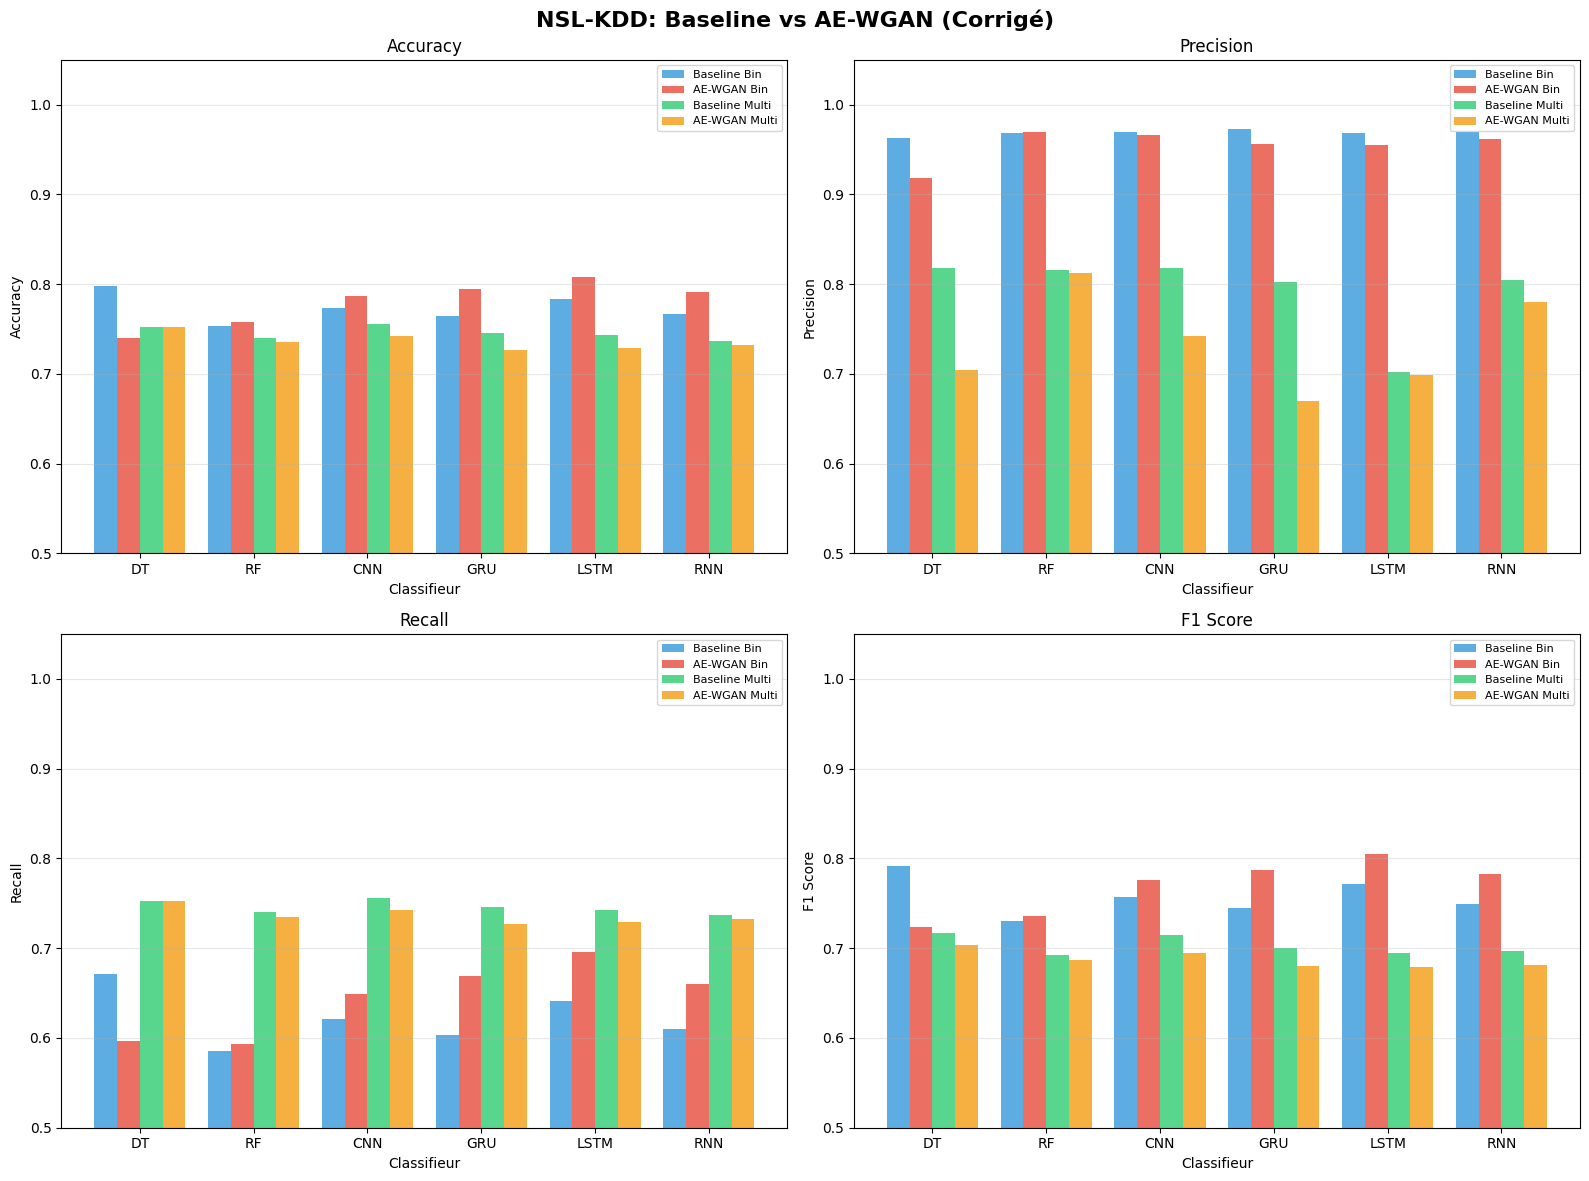

✅ Graphique sauvegardé: results_comparison_corrected.png


In [29]:
# ============================================================
# VISUALIZATION
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('NSL-KDD: Baseline vs AE-WGAN (Corrigé)', fontsize=16, fontweight='bold')

metrics = ['accuracy', 'precision', 'recall', 'f1_score']
titles = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    ax = axes[idx // 2][idx % 2]
    classifiers = [r['classifier'] for r in baseline_binary]
    x = np.arange(len(classifiers))
    w = 0.2

    vals_base_bin = [r[metric] for r in baseline_binary]
    vals_enh_bin = [r[metric] for r in enhanced_binary]
    vals_base_mul = [r[metric] for r in baseline_multi]
    vals_enh_mul = [r[metric] for r in enhanced_multi]

    ax.bar(x - 1.5*w, vals_base_bin, w, label='Baseline Bin', color='#3498db', alpha=0.8)
    ax.bar(x - 0.5*w, vals_enh_bin, w, label='AE-WGAN Bin', color='#e74c3c', alpha=0.8)
    ax.bar(x + 0.5*w, vals_base_mul, w, label='Baseline Multi', color='#2ecc71', alpha=0.8)
    ax.bar(x + 1.5*w, vals_enh_mul, w, label='AE-WGAN Multi', color='#f39c12', alpha=0.8)

    ax.set_xlabel('Classifieur')
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(classifiers)
    ax.legend(fontsize=8)
    ax.set_ylim(0.5, 1.05)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('results_comparison_corrected.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Graphique sauvegardé: results_comparison_corrected.png")

In [30]:
# ============================================================
# FULL RESULTS TABLE + CSV EXPORT
# ============================================================

all_results = []
for r in baseline_binary:
    all_results.append({**r, 'type': 'Baseline', 'classification': 'Binary'})
for r in enhanced_binary:
    all_results.append({**r, 'type': 'AE-WGAN', 'classification': 'Binary'})
for r in baseline_multi:
    all_results.append({**r, 'type': 'Baseline', 'classification': 'Multiclass'})
for r in enhanced_multi:
    all_results.append({**r, 'type': 'AE-WGAN', 'classification': 'Multiclass'})

df_results = pd.DataFrame(all_results)
df_results.to_csv('results_nslkdd_corrected.csv', index=False)

print("\n✅ Résultats sauvegardés: results_nslkdd_corrected.csv")
print(df_results.to_string(index=False))


✅ Résultats sauvegardés: results_nslkdd_corrected.csv
classifier  accuracy  precision   recall  f1_score     type classification
        DT  0.798306   0.962595 0.671784  0.791317 Baseline         Binary
        RF  0.753149   0.968058 0.585678  0.729815 Baseline         Binary
       CNN  0.773510   0.969955 0.621367  0.757481 Baseline         Binary
       GRU  0.764372   0.972603 0.603055  0.744493 Baseline         Binary
      LSTM  0.783934   0.968905 0.641004  0.771561 Baseline         Binary
       RNN  0.767122   0.969419 0.610146  0.748924 Baseline         Binary
        DT  0.739975   0.917976 0.596509  0.723125  AE-WGAN         Binary
        RF  0.757896   0.969925 0.593080  0.736074  AE-WGAN         Binary
       CNN  0.787394   0.966574 0.648952  0.776540  AE-WGAN         Binary
       GRU  0.794535   0.956575 0.669446  0.787659  AE-WGAN         Binary
      LSTM  0.808153   0.955656 0.695239  0.804908  AE-WGAN         Binary
       RNN  0.791874   0.962294 0.660251  0.7

## ✅ Pipeline terminé !

### Fichiers générés :
- `results_comparison_corrected.png` — Graphique comparatif
- `results_nslkdd_corrected.csv` — Tableau complet des résultats

### Corrections appliquées :
1. ✅ Generator 3 couches (40→80→120→output) avec sigmoid
2. ✅ Critic 3 couches (80→40→1)
3. ✅ AE intégré: Critic reçoit données encodées comme "real"
4. ✅ Optimiseur Adamax (lr=9e-5)
5. ✅ 101 epochs WGAN
6. ✅ Architectures classifieurs fidèles à Table 4
7. ✅ Preprocessing conforme au paper

In [33]:
from google.colab import files
files.download('results_nslkdd_corrected.csv')
files.download('results_comparison_corrected.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>